Lesson 4: Trainer model

Device: cuda
Epoch [1/5] | Train Loss: 0.8270 | Train Acc: 73.28% | Test Losses: 0.6277 | Test Acc: 78.89%
Epoch [2/5] | Train Loss: 0.6222 | Train Acc: 78.74% | Test Losses: 0.5886 | Test Acc: 79.73%
Epoch [3/5] | Train Loss: 0.5914 | Train Acc: 79.42% | Test Losses: 0.5770 | Test Acc: 80.51%
Epoch [4/5] | Train Loss: 0.5802 | Train Acc: 79.96% | Test Losses: 0.5839 | Test Acc: 80.15%
Epoch [5/5] | Train Loss: 0.5702 | Train Acc: 80.25% | Test Losses: 0.5691 | Test Acc: 80.62%

Final test loss: 0.5691
Final test accuracy: 80.62%


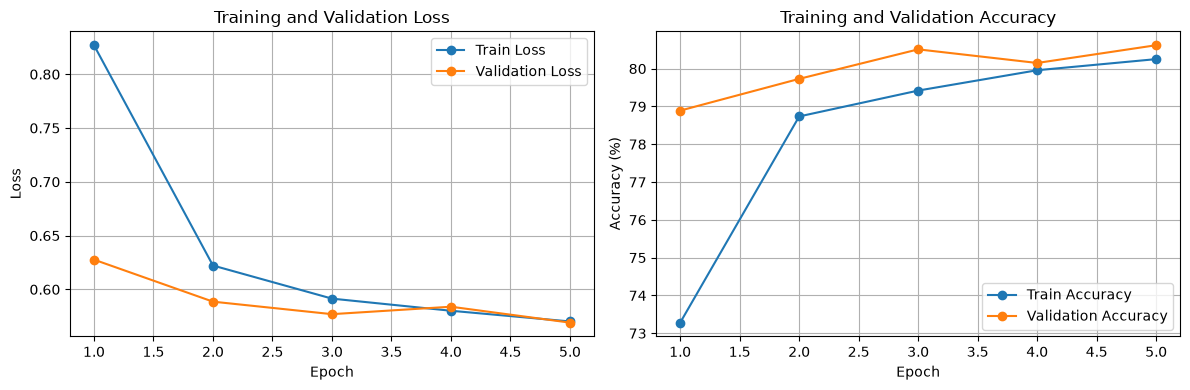

In [3]:
from pathlib import Path
import sys
import torch
import matplotlib.pyplot as plt

# Xác định thư mục project
ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.data_module import CIFAR10DataModule
from src.model_builder import TransferModelBuilder
from src.trainer import ModelTrainer

# Cấu hình
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
EPOCHS = 5
BATCH_SIZE = 64

print("Device:", DEVICE)

# Load CIFAR-10
data_module = CIFAR10DataModule(
    data_dir=str(ROOT / "data"),
    batch_size=BATCH_SIZE,
    num_workers=0,
)
data_module.setup()

train_loader = data_module.train_dataloader()
test_loader = data_module.test_dataloader()

# Khởi tạo mô hình
model = TransferModelBuilder(
    model_name="resnet18",
    num_classes=10,
    pretrained=True,
).build()

# Khởi tạo trainer
trainer = ModelTrainer(
    model=model,
    train_dataloader=train_loader,
    test_dataloader=test_loader,
    learning_rate=0.001,
    optimizer_name="Adam",
    device=DEVICE,
    weight_decay=0.0001,
)

# Huấn luyện
history = trainer.fit(num_epochs=EPOCHS)

# Đánh giá cuối cùng
test_loss, test_accuracy = trainer.evaluate()

print(f"\nFinal test loss: {test_loss:.4f}")
print(f"Final test accuracy: {test_accuracy:.2f}%")

# Vẽ biểu đồ Loss và Accuracy
epochs = range(1, EPOCHS + 1)

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(epochs, history["train_loss"], marker="o", label="Train Loss")
plt.plot(epochs, history["test_losses"], marker="o", label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(epochs, history["train_accuracy"], marker="o", label="Train Accuracy")
plt.plot(epochs, history["test_accuracy"], marker="o", label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [2]:
"""Training and validation loop utilities."""

import torch
import torch.nn as nn
import torch.optim as optim


class ModelTrainer:
    def __init__(
        self,
        model,
        train_dataloader,
        test_dataloader,
        learning_rate=0.001,
        optimizer_name="Adam",
        device=None,
        weight_decay=0.0,
    ):
        if device is None:
            device = torch.device(
                "cuda" if torch.cuda.is_available() else "cpu"
            )

        self.device = device
        self.model = model.to(self.device)

        self.train_dataloader = train_dataloader
        self.test_dataloader = test_dataloader

        # Hàm mất mát cho bài toán phân loại.
        self.criterion = nn.CrossEntropyLoss()

        # Truyền weight_decay vào optimizer để thử nghiệm L2.
        if optimizer_name == "SGD":
            self.optimizer = optim.SGD(
                self.model.parameters(),
                lr=learning_rate,
                momentum=0.9,
                weight_decay=weight_decay,
            )
        elif optimizer_name == "Adam":
            self.optimizer = optim.Adam(
                self.model.parameters(),
                lr=learning_rate,
                weight_decay=weight_decay,
            )
        else:
            raise ValueError("Optimizer_name must be 'SGD' or 'Adam'")

    def training_loop(self):
        self.model.train()

        total_loss = 0.0
        correct = 0
        total = 0

        for images, labels in self.train_dataloader:
            images = images.to(self.device)
            labels = labels.to(self.device)

            # Xóa gradient của bước trước.
            self.optimizer.zero_grad()

            # Dự đoán và tính loss.
            outputs = self.model(images)
            loss = self.criterion(outputs, labels)

            # Tính gradient và cập nhật trọng số.
            loss.backward()
            self.optimizer.step()

            # Cộng dồn loss và số dự đoán đúng.
            total_loss += loss.item() * images.size(0)
            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

        avg_loss = total_loss / total
        accuracy = 100.0 * correct / total

        return avg_loss, accuracy

    def evaluate(self):
        self.model.eval()

        total_loss = 0.0
        correct = 0
        total = 0

        with torch.no_grad():
            for images, labels in self.test_dataloader:
                images = images.to(self.device)
                labels = labels.to(self.device)

                outputs = self.model(images)
                loss = self.criterion(outputs, labels)

                total_loss += loss.item() * images.size(0)
                _, predicted = torch.max(outputs, 1)

                total += labels.size(0)
                correct += (predicted == labels).sum().item()

        avg_loss = total_loss / total
        accuracy = 100.0 * correct / total

        return avg_loss, accuracy

    def fit(self, num_epochs):
        history = {
            "train_loss": [],
            "train_accuracy": [],
            "test_losses": [],
            "test_accuracy": [],
        }

        for epoch in range(num_epochs):
            train_loss, train_acc = self.training_loop()
            test_loss, test_acc = self.evaluate()

            history["train_loss"].append(train_loss)
            history["train_accuracy"].append(train_acc)
            history["test_losses"].append(test_loss)
            history["test_accuracy"].append(test_acc)

            print(
                f"Epoch [{epoch + 1}/{num_epochs}] | "
                f"Train Loss: {train_loss:.4f} | "
                f"Train Acc: {train_acc:.2f}% | "
                f"Test Losses: {test_loss:.4f} | "
                f"Test Acc: {test_acc:.2f}%"
            )

        return history